# 実験結果を自分でグラフにする

このノートブックでは、実験結果のCSVを自分で読み込み、グラフを作ります。セルを上から順に実行してください。

まず `summary.csv` の平均と標準偏差を使って、学習データ中の申込あり比率・データ量と Recall の関係を描きます。最後に、5回の試行結果を点で表示して、平均だけでは見えないばらつきも確認します。

**試してみること:** `METRIC` を `"recall"` から `"f1"` に変える、`SELECTED_RATIO` を `0.10` から `0.30` に変えるなど、値を変更して再実行してみてください。

**実行前に:** VS Code右上のカーネル名をクリックし、`Python (research .venv)` を選んでください。最初のコードセルに表示されるPythonの場所が `research/.venv/Scripts/python.exe` であることを確認します。

In [2]:
import sys
from importlib.util import find_spec
from pathlib import Path

print(f"使用中のPython: {sys.executable}")
if find_spec("matplotlib") is None:
    raise ModuleNotFoundError(
        "このカーネルにmatplotlibがありません。VS Code右上のカーネル名から "
        "Python (research .venv) を選び、カーネルを再起動してください。"
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# VS Codeがノートブックの場所またはプロジェクト直下を作業場所にしても動くように探します。
HERE = Path.cwd()
possible_roots = [HERE, HERE.parent, HERE / "research"]
PROJECT_DIR = next(
    (path for path in possible_roots if (path / "results" / "summary.csv").exists()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("research/results/summary.csv が見つかりません。プロジェクトの research フォルダを確認してください。")

RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
print(f"プロジェクト: {PROJECT_DIR.resolve()}")

使用中のPython: c:\Users\14092\graduation\research\.venv\Scripts\python.exe
プロジェクト: C:\Users\14092\graduation\research


In [3]:
summary = pd.read_csv(RESULTS_DIR / "summary.csv")
print(f"条件ごとの集計行数: {len(summary)}")
print("モデル:", summary["model"].unique().tolist())
display(summary.head())

条件ごとの集計行数: 40
モデル: ['logistic_regression', 'random_forest']


,model,n_train,minority_ratio,n_seeds,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std
0,logistic_regression,500,0.01,5,0.882925,0.000338,0.293182,0.364558,0.001134,0.001366,0.002258,0.002720,0.210535,0.057439
1,logistic_regression,500,0.05,5,0.885668,0.002491,0.566328,0.253647,0.047889,0.033930,0.087117,0.060675,0.280174,0.066342
2,logistic_regression,500,0.10,5,0.888779,0.002958,0.611635,0.052871,0.134846,0.055255,0.216601,0.076428,0.334765,0.024586
3,logistic_regression,500,0.30,5,0.853568,0.008643,0.379438,0.027211,0.390170,0.007850,0.384451,0.017127,0.358024,0.020405
4,logistic_regression,500,0.50,5,0.702315,0.025915,0.228261,0.012515,0.643478,0.037383,0.336363,0.008909,0.357105,0.022435


## 1. 申込あり比率とRecallをプロットする

横軸は学習データ中の申込あり比率、縦軸はテストデータでのRecallです。線の色は学習データ量を表します。縦のエラーバーは、5回の抽出結果の標準偏差です。

`METRIC` を `"f1"`、`"accuracy"`、`"pr_auc"` に変えると、別の指標を表示できます。

C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2282047406.py:29: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2282047406.py:29: UserWarning: Glyph 32722 (\N{CJK UNIFIED IDEOGRAPH-7FD2}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2282047406.py:29: UserWarning: Glyph 12487 (\N{KATAKANA LETTER DE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2282047406.py:29: UserWarning: Glyph 12540 (\N{KATAKANA-HIRAGANA PROLONGED SOUND MARK}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2282047406.py:29: UserWarning: Glyph 12479 (\N{KATAKANA LETTER TA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2282047406.py:29: UserWarning: Glyph 20013 (\N{CJ

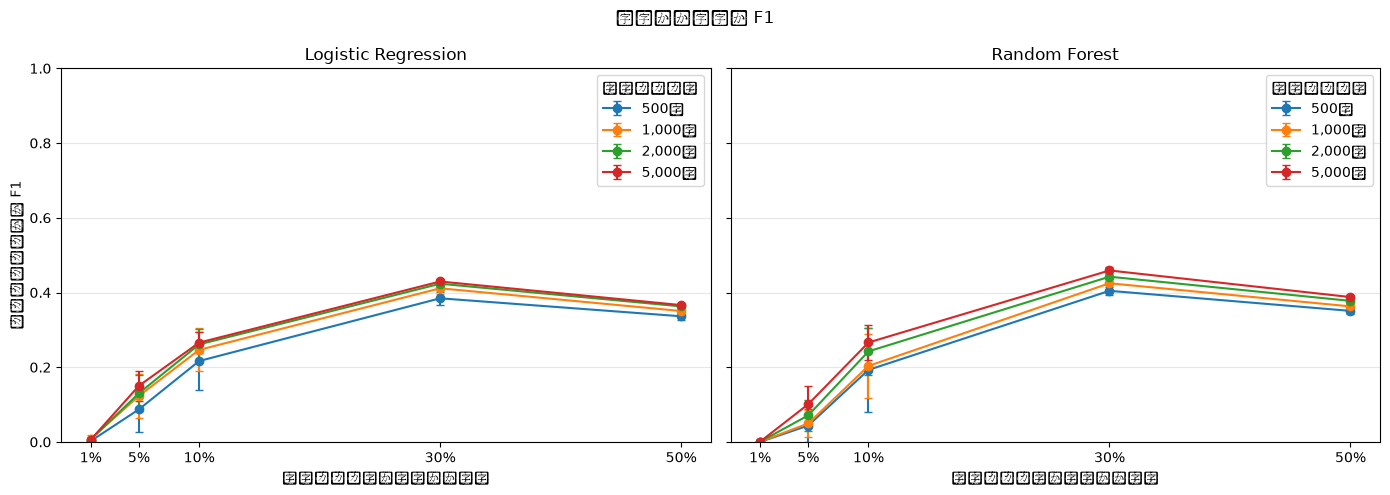

In [8]:
METRIC = "f1"  # 例: "f1" や "accuracy" に変更
RATIOS = [0.01, 0.05, 0.10, 0.30, 0.50]
TRAIN_SIZES = [500, 1_000, 2_000, 5_000]
MODELS = ["logistic_regression", "random_forest"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, model_name in zip(axes, MODELS):
    model_data = summary[summary["model"] == model_name]
    for n_train in TRAIN_SIZES:
        line = (
            model_data[model_data["n_train"] == n_train]
            .sort_values("minority_ratio")
        )
        ax.errorbar(
            line["minority_ratio"] * 100,
            line[f"{METRIC}_mean"],
            yerr=line[f"{METRIC}_std"],
            marker="o", capsize=3, label=f"{n_train:,}件"
        )
    ax.set_xticks([ratio * 100 for ratio in RATIOS])
    ax.set_xticklabels([f"{ratio:.0%}" for ratio in RATIOS])
    ax.set_xlabel("学習データ中の申込あり比率")
    ax.set_title(model_name.replace("_", " ").title())
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="学習データ量")
axes[0].set_ylabel(f"テストデータでの {METRIC.upper()}")
fig.suptitle(f"申込あり比率と {METRIC.upper()}")
fig.tight_layout()
plt.show()

## 2. 学習データ量とRecallをプロットする

今度は学習データ量を横軸にします。`SELECTED_RATIO` を変えて、比率ごとにデータ量の増加がどう見えるか比べてください。

C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2236216752.py:22: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2236216752.py:22: UserWarning: Glyph 32722 (\N{CJK UNIFIED IDEOGRAPH-7FD2}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2236216752.py:22: UserWarning: Glyph 12487 (\N{KATAKANA LETTER DE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2236216752.py:22: UserWarning: Glyph 12540 (\N{KATAKANA-HIRAGANA PROLONGED SOUND MARK}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2236216752.py:22: UserWarning: Glyph 12479 (\N{KATAKANA LETTER TA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\14092\AppData\Local\Temp\ipykernel_14212\2236216752.py:22: UserWarning: Glyph 37327 (\N{CJ

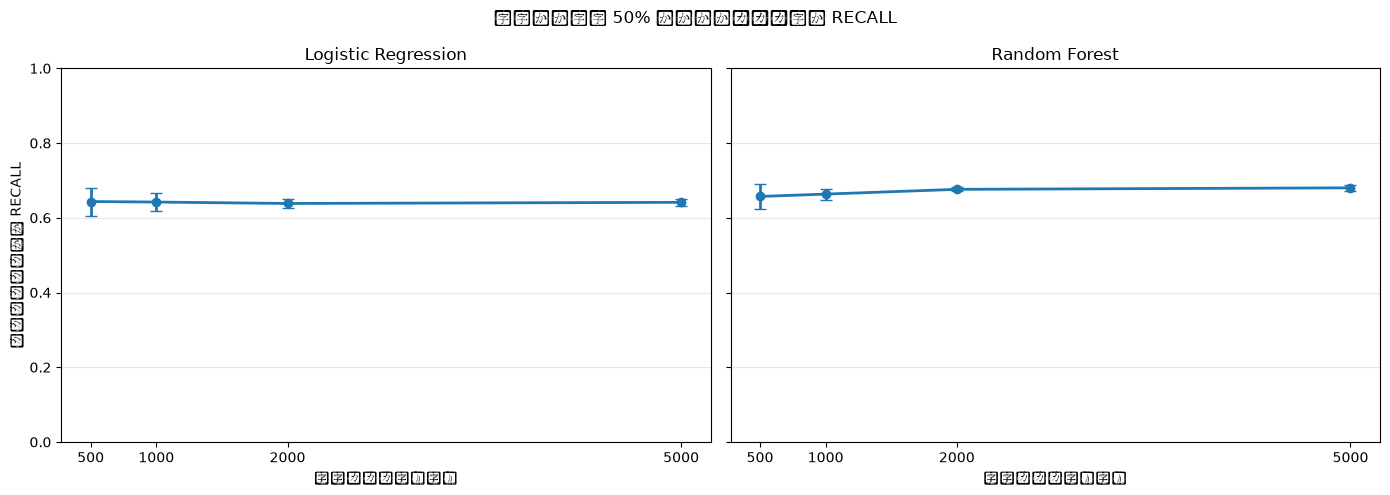

In [7]:
SELECTED_RATIO = 0.50  # 0.01, 0.05, 0.10, 0.30, 0.50 から選ぶ

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, model_name in zip(axes, MODELS):
    model_data = summary[
        (summary["model"] == model_name)
        & (summary["minority_ratio"] == SELECTED_RATIO)
    ].sort_values("n_train")
    ax.errorbar(
        model_data["n_train"],
        model_data[f"{METRIC}_mean"],
        yerr=model_data[f"{METRIC}_std"],
        marker="o", capsize=4, linewidth=2
    )
    ax.set_xticks(TRAIN_SIZES)
    ax.set_xlabel("学習データ量（件）")
    ax.set_title(model_name.replace("_", " ").title())
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel(f"テストデータでの {METRIC.upper()}")
fig.suptitle(f"申込あり比率 {SELECTED_RATIO:.0%} のときのデータ量と {METRIC.upper()}")
fig.tight_layout()
plt.show()

## 3. 平均の元になった5回分を点で見る

集計表だけでなく、個々の試行結果も見てみましょう。下の点はそれぞれ異なる乱数シードで学習データを選んだ1回分の結果です。点の散らばりが大きい比率があるかを確認します。

c:\Users\14092\graduation\research\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 22238 (\N{CJK UNIFIED IDEOGRAPH-56DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\14092\graduation\research\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 12372 (\N{HIRAGANA LETTER GO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\14092\graduation\research\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 12392 (\N{HIRAGANA LETTER TO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\14092\graduation\research\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 12398 (\N{HIRAGANA LETTER NO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\14092\graduation\research\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 12539 (\N{KATA

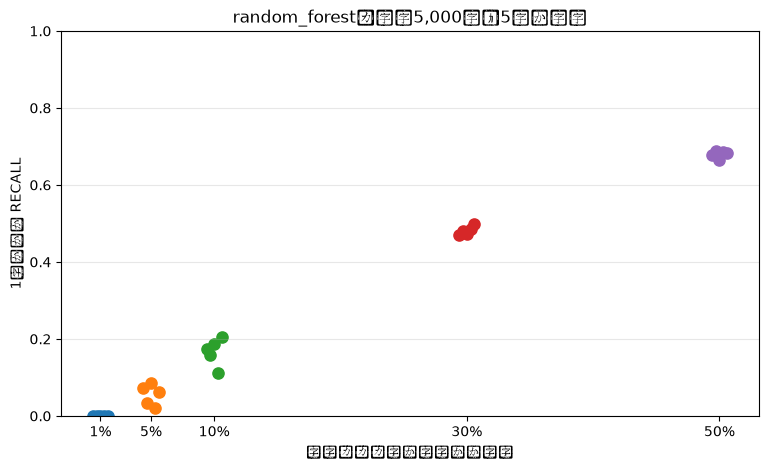

In [6]:
runs = pd.read_csv(RESULTS_DIR / "results_2026-10-26.csv")
MODEL_TO_INSPECT = "random_forest"
SIZE_TO_INSPECT = 5_000

selected = runs[
    (runs["model"] == MODEL_TO_INSPECT)
    & (runs["n_train"] == SIZE_TO_INSPECT)
].copy()

fig, ax = plt.subplots(figsize=(9, 5))
for ratio in RATIOS:
    points = selected[selected["minority_ratio"] == ratio].sort_values("seed")
    # 5つの点が重なりにくいよう、横方向に少しだけずらします。
    offsets = np.linspace(-0.6, 0.6, len(points))
    ax.scatter(
        ratio * 100 + offsets, points[METRIC],
        s=65, label=f"{ratio:.0%}"
    )
ax.set_xticks([ratio * 100 for ratio in RATIOS])
ax.set_xticklabels([f"{ratio:.0%}" for ratio in RATIOS])
ax.set_xlabel("学習データ中の申込あり比率")
ax.set_ylabel(f"1回ごとの {METRIC.upper()}")
ax.set_title(f"{MODEL_TO_INSPECT}・学習{SIZE_TO_INSPECT:,}件：5回の試行")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.show()

## 自分の言葉で説明してみる

グラフを見て、次の問いにノートや発表資料用のメモとして答えてみてください。

1. 申込あり比率を1%から50%に変えると、Recallはどう変わるか。
2. 学習データ量を増やしたとき、変化が大きい比率・小さい比率はどこか。
3. 平均値の線だけを見る場合と、5回分の点を見る場合で、気づくことはどう違うか。
4. `METRIC = "f1"` に変えたとき、Recallのグラフと結論は同じになるか。

**保存の練習:** 描画セルの最後に `fig.savefig(FIGURES_DIR / "my_plot.png", dpi=200, bbox_inches="tight")` を追加すると、自分で作った図を `research/figures` に保存できます。